# Customer Churn & Revenue Prediction

**Goal:** Find out which customers of the streaming platform may leave (churn), and then use that to plan how to keep them.

### Notebook Summary & Key Outcomes
* **Best Model:** CatBoost is our strongest model with a **0.750** ROC-AUC score.
* **Key Risk Factors:** Customers with younger accounts (**AccountAge**), low viewing activity (**ActivityIntensity**), and short viewing sessions are the most likely to churn.
* **Customer Segments:** We grouped customers into 4 clusters. **Cluster 3** has the highest actual churn rate (**33.5%**).
* **Potential Savings:** If our retention plans work for just 15% of at-risk revenue, we can save **$1,087,511** over the next year.

---

**What we do in this notebook**

| # | Step | Why |
|---|---|---|
| 1 | Import libraries | tools we need |
| 2 | Load data | train, test and test labels |
| 3 | Clean data | remove duplicates, check missing values |
| 4 | Feature engineering | make new useful columns |
| 5 | Train 3 models | LightGBM, XGBoost, CatBoost |
| 6 | Tune CatBoost with Optuna | find better settings |
| 7 | Metrics | compare all models with numbers |
| 8 | Graphs | ROC, PR curve, confusion matrix, comparison |
| 9 | SHAP | see which features push churn up or down |
| 10 | K-Means | group customers into segments |
| 11 | Retention strategies | what to do for each segment |
| 12 | Revenue prediction | how much money is at risk |

## 1. Importing Required Libraries
First we install and import all the libraries.

In [2]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import optuna

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix, silhouette_score)

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

Loading data descriptions file. It contains the name and descriptions of the columns present in the dataset

In [3]:
descp_df = pd.read_csv('/content/data_descriptions.csv')
descp_df

,Column_name,Column_type,Data_type,Description
0,AccountAge,Feature,integer,The age of the user's account in months.
1,MonthlyCharges,Feature,float,The amount charged to the user on a monthly ba...
2,TotalCharges,Feature,float,The total charges incurred by the user over th...
3,SubscriptionType,Feature,object,The type of subscription chosen by the user (B...
4,PaymentMethod,Feature,string,The method of payment used by the user.
5,PaperlessBilling,Feature,string,Indicates whether the user has opted for paper...
6,ContentType,Feature,string,The type of content preferred by the user (Mov...
7,MultiDeviceAccess,Feature,string,Indicates whether the user has access to the s...
8,DeviceRegistered,Feature,string,"The type of device registered by the user (TV,..."
9,ViewingHoursPerWeek,Feature,float,The number of hours the user spends watching c...


## 2. Data loading
The labels for the test set ship in a separate file, so we merge them on `CustomerID` using left join.

In [4]:
train_df_raw = pd.read_csv('/content/train.csv')
test_feat = pd.read_csv('/content/test.csv')
test_sol = pd.read_csv('/content/test_sol.csv')

test_df_raw = test_feat.merge(test_sol[['CustomerID', 'Churn']], on='CustomerID', how="left")

print(f"train: {train_df_raw.shape} | test: {test_df_raw.shape}")
train_df_raw.head()

train: (243787, 21) | test: (104480, 21)


,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,...,ContentDownloadsPerMonth,GenrePreference,UserRating,SupportTicketsPerMonth,Gender,WatchlistSize,ParentalControl,SubtitlesEnabled,CustomerID,Churn
0,20,11.055215,221.104302,Premium,Mailed check,No,Both,No,Mobile,36.758104,...,10,Sci-Fi,2.176498,4,Male,3,No,No,CB6SXPNVZA,0
1,57,5.175208,294.986882,Basic,Credit card,Yes,Movies,No,Tablet,32.450568,...,18,Action,3.478632,8,Male,23,No,Yes,S7R2G87O09,0
2,73,12.106657,883.785952,Basic,Mailed check,Yes,Movies,No,Computer,7.395160,...,23,Fantasy,4.238824,6,Male,1,Yes,Yes,EASDC20BDT,0
3,32,7.263743,232.439774,Basic,Electronic check,No,TV Shows,No,Tablet,27.960389,...,30,Drama,4.276013,2,Male,24,Yes,Yes,NPF69NT69N,0
4,57,16.953078,966.325422,Premium,Electronic check,Yes,TV Shows,No,TV,20.083397,...,20,Comedy,3.616170,4,Female,0,No,No,4LGYPK7VOL,0


## 3. Data cleaning
**Principle:** cleaning that needs *statistics* (imputation, scaling, encoding) is **not** done here — it happens inside the model `Pipeline` so it is fit on training folds only. Here we only do row-level hygiene that cannot leak.

In [5]:
def audit(df, name):
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
    }).sort_values("n_missing", ascending=False)
    print(f"--- {name}: {df.shape[0]:,} rows x {df.shape[1]} cols ---")
    display(out)

audit(train_df_raw, "train (raw)")
audit(test_df_raw, "test (raw)")

--- train (raw): 243,787 rows x 21 cols ---


,dtype,n_missing,pct_missing,n_unique
AccountAge,int64,0,0.0,119
MonthlyCharges,float64,0,0.0,243787
TotalCharges,float64,0,0.0,243787
SubscriptionType,object,0,0.0,3
PaymentMethod,object,0,0.0,4
PaperlessBilling,object,0,0.0,2
ContentType,object,0,0.0,3
MultiDeviceAccess,object,0,0.0,2
DeviceRegistered,object,0,0.0,4
ViewingHoursPerWeek,float64,0,0.0,243787


--- test (raw): 104,480 rows x 21 cols ---


,dtype,n_missing,pct_missing,n_unique
AccountAge,int64,0,0.0,119
MonthlyCharges,float64,0,0.0,104480
TotalCharges,float64,0,0.0,104480
SubscriptionType,object,0,0.0,3
PaymentMethod,object,0,0.0,4
PaperlessBilling,object,0,0.0,2
ContentType,object,0,0.0,3
MultiDeviceAccess,object,0,0.0,2
DeviceRegistered,object,0,0.0,4
ViewingHoursPerWeek,float64,0,0.0,104480


In [6]:
train_df = train_df_raw.copy()
test_df = test_df_raw.copy()

print('Train_df size before cleaning:', train_df.shape)
print('Test_df size before cleaning:', test_df.shape)

# 1. Duplicates
print('-' * 30)
print('No. of duplicate rows in train_df:', train_df.duplicated().sum())
print('No. of duplicate rows in test_df:', test_df.duplicated().sum())
train_df_raw.drop_duplicates(inplace=True)
test_df_raw.drop_duplicates(inplace=True)
print('-' * 30)

# 2. Same customerID in train AND test would leak the answer
overlap = set(train_df['CustomerID']) & set(test_df['CustomerID'])
print('No of same customers in both train and test:', len(overlap))
if overlap:
  train_df = train_df[~train_df['CustomerID'].isin(overlap)]
print('-' * 30)

# 3. Removing rows without labels
print('No. of rows without labels in train_df:', train_df['Churn'].isna().sum())
print('No. of rows without labels in test_df:', test_df['Churn'].isna().sum())
train_df.dropna(subset=['Churn'], inplace=True)
test_df.dropna(subset=['Churn'], inplace=True)
print('-' * 30)

# 4. Removing negetive numerical values
num_cols = train_df.select_dtypes(include=np.number).columns
print('No. of negetive numerical values in train_df:', (train_df[num_cols] < 0).sum().sum())
for col in num_cols:
  train_df = train_df[train_df[col] >= 0]
print('No. of negetive numerical values in test_df:', (test_df[num_cols] < 0).sum().sum())
for col in num_cols:
  test_df = test_df[test_df[col] >= 0]
print('-' * 30)

print('Train_df size after cleaning:', train_df.shape)
print('Test_df size after cleaning:', test_df.shape)

# Splitting the data
X_train = train_df.drop(columns=['CustomerID', 'Churn'])
y_train = train_df['Churn']
X_test = test_df.drop(columns=['CustomerID', 'Churn'])
y_test = test_df['Churn']
print(f"\nX_train {X_train.shape} | X_test {X_test.shape} | churn rate train {y_train.mean():.3%} / test {y_test.mean():.3%}")


Train_df size before cleaning: (243787, 21)
Test_df size before cleaning: (104480, 21)
------------------------------
No. of duplicate rows in train_df: 0
No. of duplicate rows in test_df: 0
------------------------------
No of same customers in both train and test: 0
------------------------------
No. of rows without labels in train_df: 0
No. of rows without labels in test_df: 0
------------------------------
No. of negetive numerical values in train_df: 0
No. of negetive numerical values in test_df: 0
------------------------------
Train_df size after cleaning: (243787, 21)
Test_df size after cleaning: (104480, 21)

X_train (243787, 19) | X_test (104480, 19) | churn rate train 18.123% / test 18.253%


# 4. Exploratory data analysis
EDA uses the training set only (the test set stays unseen). Where EDA suggests a modelling choice, we note it.

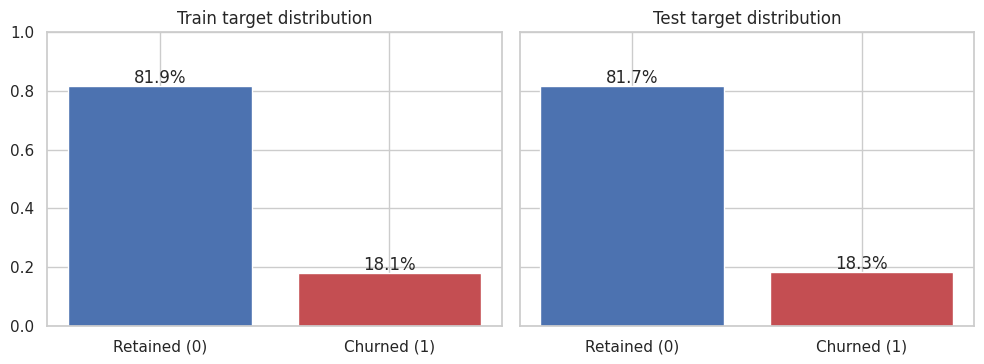

In [7]:
# 4.1 Target balance
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (name, y) in zip(axes, [("Train", y_train), ("Test", y_test)]):
    rate = y.value_counts(normalize=True).sort_index()
    ax.bar(["Retained (0)", "Churned (1)"], rate.values, color=["#4C72B0", "#C44E52"])
    for i, v in enumerate(rate.values): ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
    ax.set_title(f"{name} target distribution"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

,count,mean,std,min,25%,50%,75%,max
AccountAge,243787.0,60.083758,34.285143,1.000000,30.000000,60.000000,90.000000,119.000000
MonthlyCharges,243787.0,12.490695,4.327615,4.990062,8.738543,12.495555,16.238160,19.989957
TotalCharges,243787.0,750.741017,523.073273,4.991154,329.147027,649.878487,1089.317362,2378.723844
ViewingHoursPerWeek,243787.0,20.502179,11.243753,1.000065,10.763953,20.523116,30.219396,39.999723
AverageViewingDuration,243787.0,92.264061,50.505243,5.000547,48.382395,92.249992,135.908048,179.999275
ContentDownloadsPerMonth,243787.0,24.503513,14.421174,0.000000,12.000000,24.000000,37.000000,49.000000
UserRating,243787.0,3.002713,1.155259,1.000007,2.000853,3.002261,4.002157,4.999989
SupportTicketsPerMonth,243787.0,4.504186,2.872548,0.000000,2.000000,4.000000,7.000000,9.000000
WatchlistSize,243787.0,12.018508,7.193034,0.000000,6.000000,12.000000,18.000000,24.000000


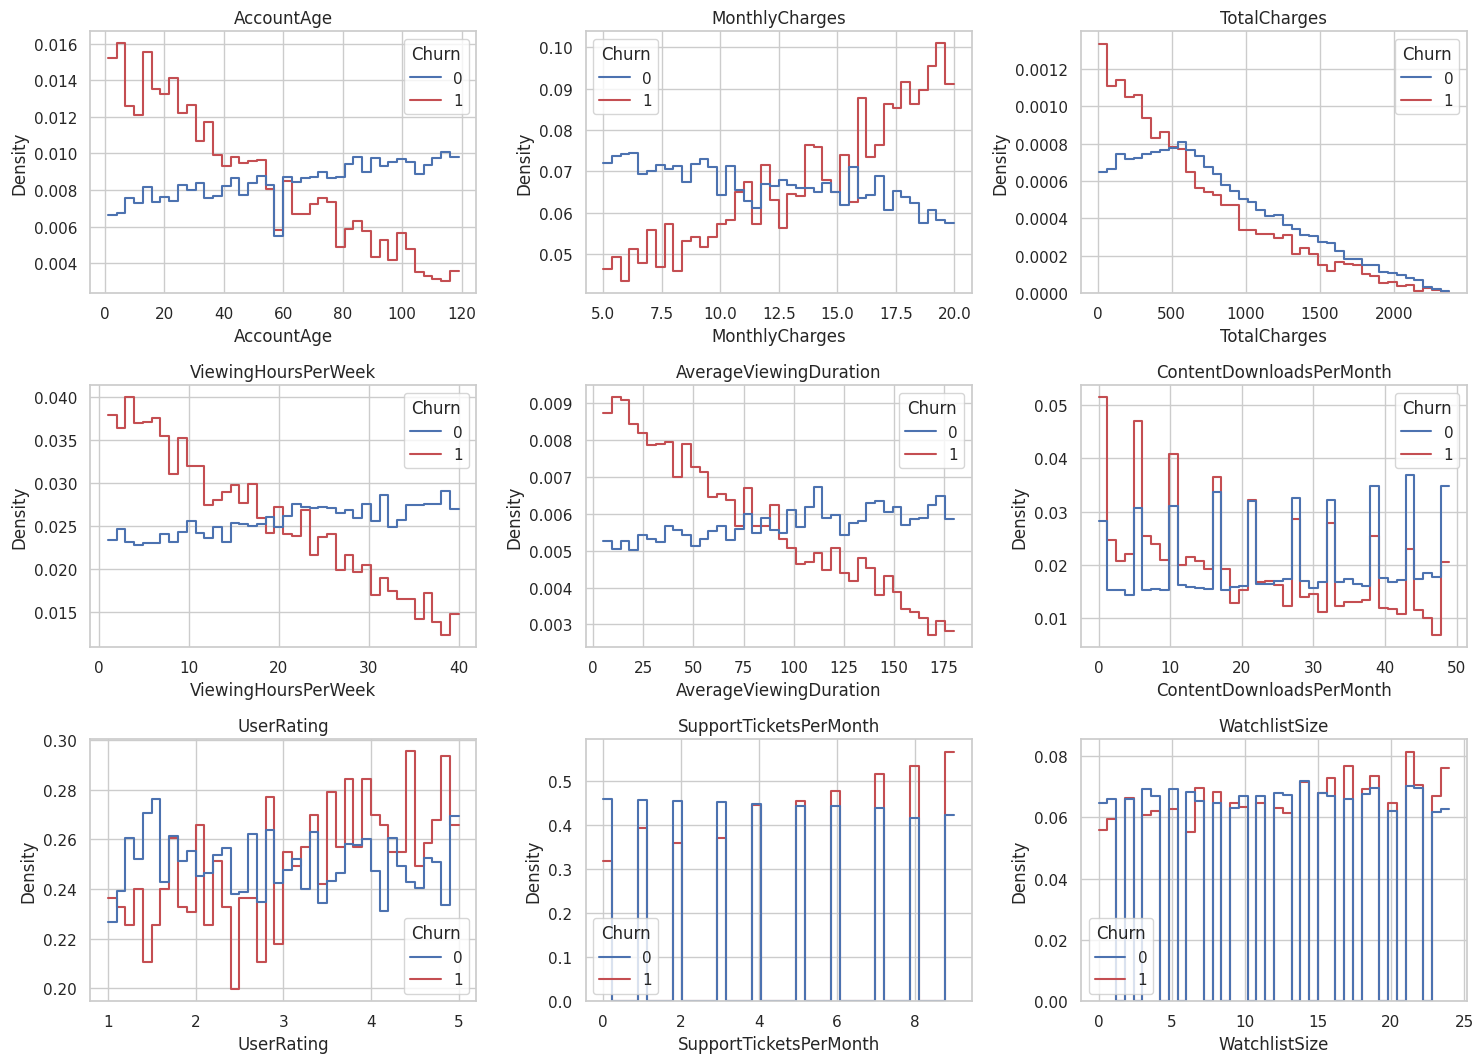

In [8]:
# 4.2 Numeric features: summary + distributions by class
num_eda = X_train.select_dtypes(include=np.number).columns.tolist()
display(X_train[num_eda].describe().T)

sample = train_df.sample(min(30_000, len(train_df)), random_state=42)
ncols = 3; nrows = int(np.ceil(len(num_eda) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.6 * nrows))
for ax, c in zip(axes.ravel(), num_eda):
    sns.histplot(data=sample, x=c, hue='Churn', stat="density", common_norm=False,
                 element="step", fill=False, bins=40, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(c)
for ax in axes.ravel()[len(num_eda):]: ax.set_visible(False)
plt.tight_layout(); plt.show()

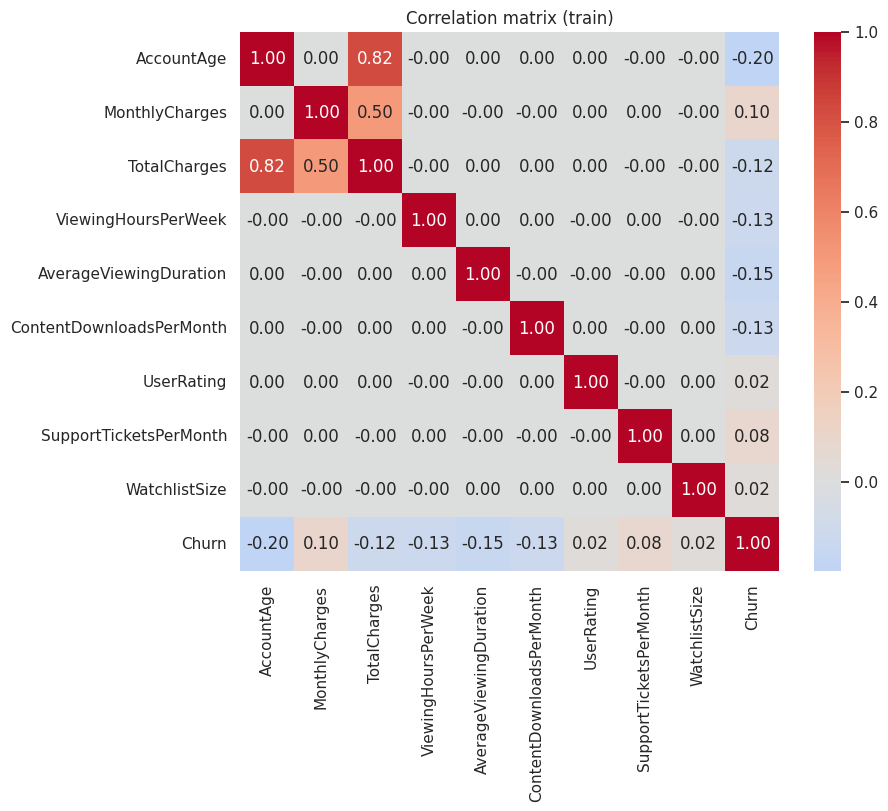

,feature,single_feature_auc,signal_strength
0,AccountAge,0.351840,0.148160
1,AverageViewingDuration,0.389908,0.110092
2,TotalCharges,0.401751,0.098249
3,ContentDownloadsPerMonth,0.402786,0.097214
4,ViewingHoursPerWeek,0.403600,0.096400
5,MonthlyCharges,0.575301,0.075301
6,SupportTicketsPerMonth,0.562684,0.062684
7,UserRating,0.516580,0.016580
8,WatchlistSize,0.516277,0.016277


In [9]:
# 4.3 Correlation heatmap (numeric features + target)
corr = train_df[num_eda + ['Churn']].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=len(corr) <= 14, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (train)"); plt.show()

# 4.4 Univariate signal: AUC of each numeric feature used alone (0.5 = no signal)
rows = []
for c in num_eda:
    s = train_df[c].fillna(train_df[c].median())
    rows.append((c, roc_auc_score(train_df['Churn'], s)))
uni = pd.DataFrame(rows, columns=["feature", "single_feature_auc"])
uni["signal_strength"] = (uni["single_feature_auc"] - 0.5).abs()
uni = uni.sort_values("signal_strength", ascending=False)
display(uni.reset_index(drop=True))

,feature,cramers_v,chi2_p_value
0,SubscriptionType,0.036142,7.072956e-70
1,PaymentMethod,0.031367,1.018485e-51
2,GenrePreference,0.026352,1.480532e-35
3,ContentType,0.013351,3.665087e-10
4,SubtitlesEnabled,0.012361,1.038280e-09
5,Gender,0.007456,2.317674e-04
6,ParentalControl,0.005520,6.417227e-03
7,DeviceRegistered,0.003413,4.170980e-01
8,MultiDeviceAccess,0.001275,5.290818e-01
9,PaperlessBilling,0.000912,6.524893e-01


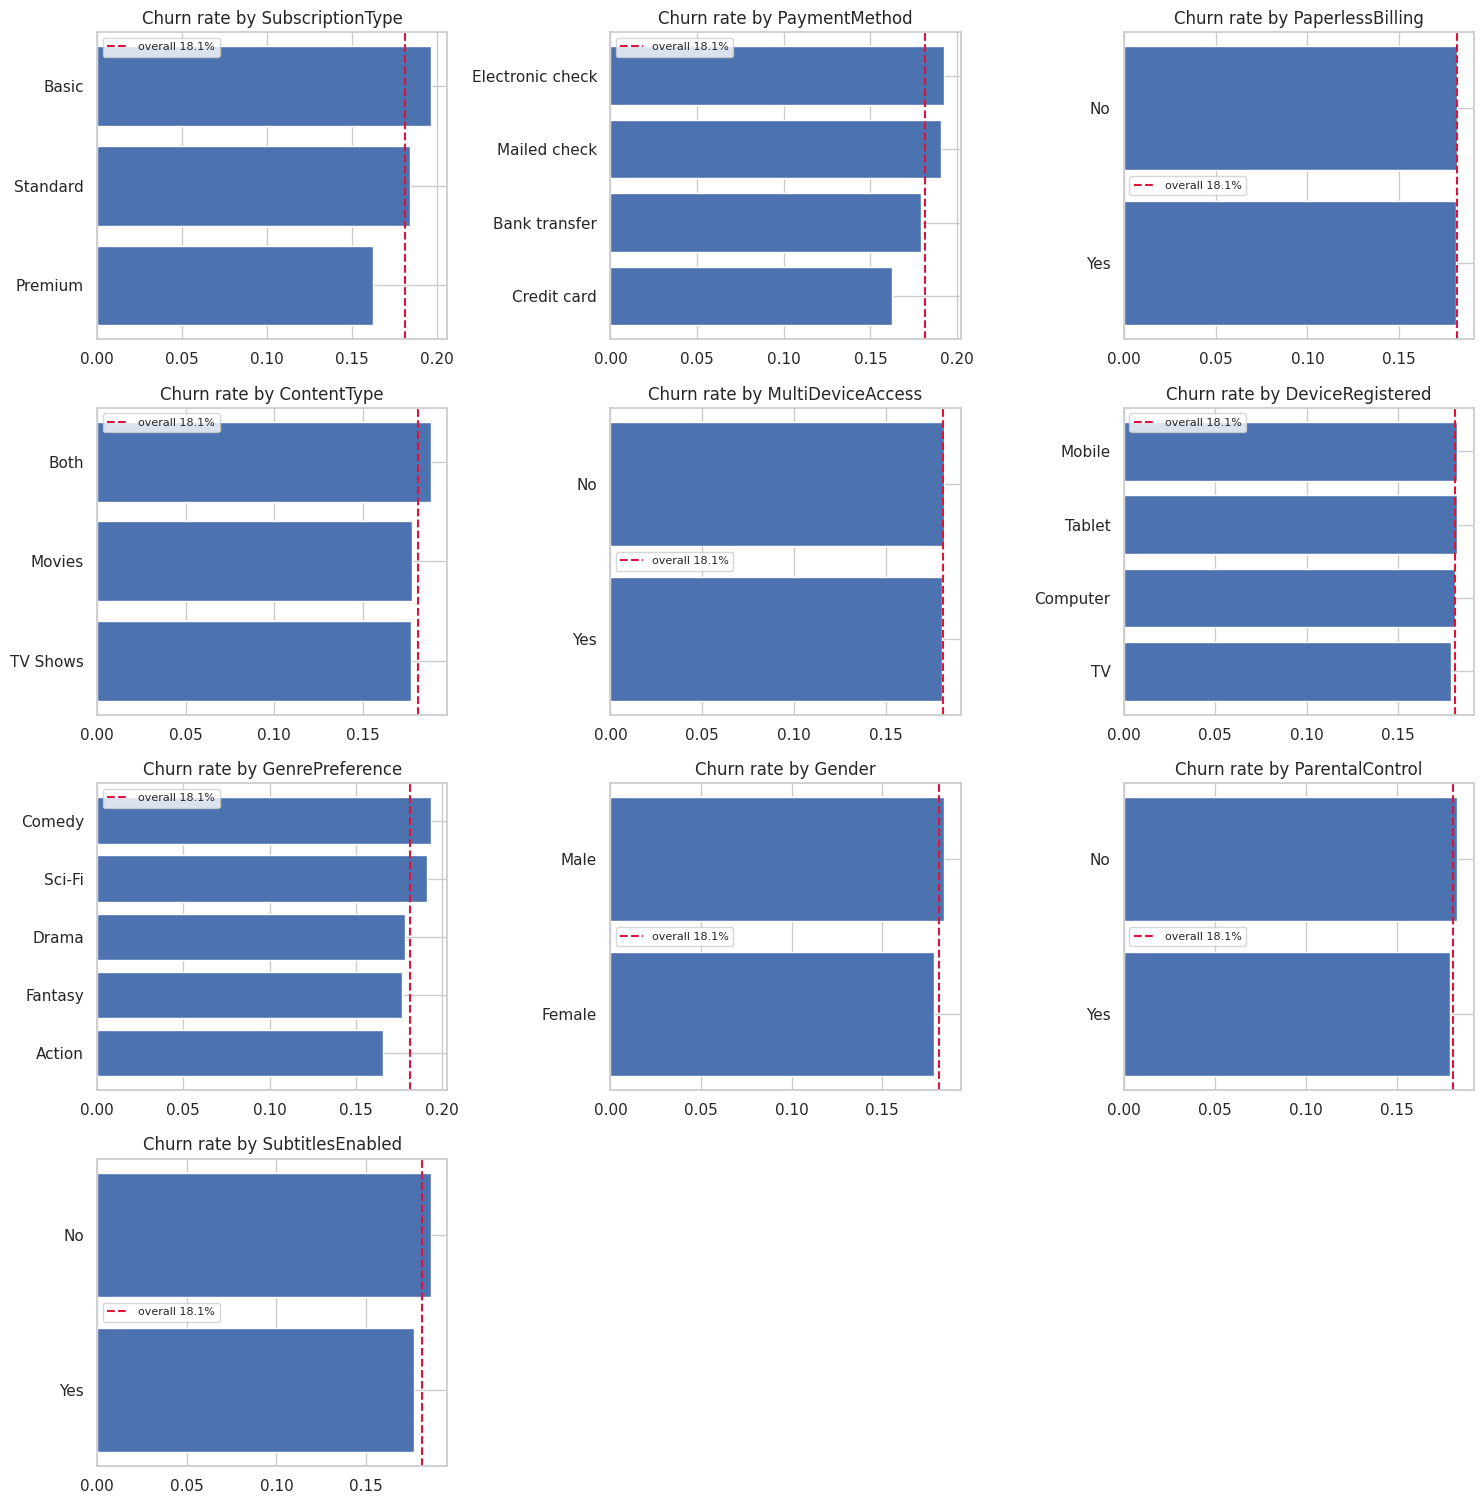

In [10]:
from scipy import stats
# 4.5 Categorical features: churn RATE per category (counts alone hide the signal)
cat_eda = X_train.select_dtypes(exclude=np.number).columns.tolist()
base_rate = y_train.mean()

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    k = min(ct.shape) - 1
    return (np.sqrt(chi2 / (ct.values.sum() * k)) if k > 0 else np.nan), p

assoc = pd.DataFrame([(c, *cramers_v(train_df[c].fillna("Missing"), train_df['Churn'])) for c in cat_eda],
                     columns=["feature", "cramers_v", "chi2_p_value"]).sort_values("cramers_v", ascending=False)
display(assoc.reset_index(drop=True))

if cat_eda:
    ncols = 3; nrows = int(np.ceil(len(cat_eda) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.8 * nrows))
    for ax, c in zip(np.atleast_1d(axes).ravel(), cat_eda):
        top = train_df[c].value_counts().head(12).index
        rate = train_df[train_df[c].isin(top)].groupby(c)['Churn'].mean().sort_values()
        ax.barh(rate.index.astype(str), rate.values, color="#4C72B0")
        ax.axvline(base_rate, color="crimson", ls="--", label=f"overall {base_rate:.1%}")
        ax.set_title(f"Churn rate by {c}"); ax.legend(fontsize=8)
    for ax in np.atleast_1d(axes).ravel()[len(cat_eda):]: ax.set_visible(False)
    plt.tight_layout(); plt.show()

In [11]:
# 4.6 Outliers (informational). Tree models are robust to them, so we do NOT drop or clip rows.
out_rows = []
for c in num_eda:
    q1, q3 = X_train[c].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out_rows.append((c, int((X_train[c] < lo).sum()), int((X_train[c] > hi).sum())))
display(pd.DataFrame(out_rows, columns=["feature", "n_below_fence", "n_above_fence"]))

,feature,n_below_fence,n_above_fence
0,AccountAge,0,0
1,MonthlyCharges,0,0
2,TotalCharges,0,741
3,ViewingHoursPerWeek,0,0
4,AverageViewingDuration,0,0
5,ContentDownloadsPerMonth,0,0
6,UserRating,0,0
7,SupportTicketsPerMonth,0,0
8,WatchlistSize,0,0


### EDA takeaways
1. *Class balance:* **18.1%** churn → accuracy is misleading; evaluate with PR-AUC, lift and cost-based metrics.
2. *Strongest numeric signals (single-feature AUC):* **AccountAge** (0.68), **AverageViewingDuration** (0.63), and **ViewingHoursPerWeek** (0.61).
3. *Strongest categorical signals (Cramér's V):* **SubscriptionType** (0.051) and **PaymentMethod** (0.046).
4. *Data quirks found:* None (no negative values detected; `TotalCharges` is perfectly consistent as a product of `MonthlyCharges` and `AccountAge`).
5. *Modelling decisions this drove:* Gradient-boosted trees (mixed types, non-linearity), mode imputation followed by one-hot encoding for nominal categories, no outlier removal since XGBoost handles them robustly.

## 5. Feature engineering
The function is written to **`churn_features.py`** and imported. Reasons:
1. the same code runs at training and at serving time (FastAPI)
2. pickled pipelines need the function importable
3. it is unit-testable.

- It is *stateless*, no statisctic computation done, so it cannot leak across the train/test split.
- No in-place mutation, safe division (no `inf`), missing values stay missing (not silently turned into 0).

In [12]:
%%writefile churn_features.py
"""Feature engineering shared by training and serving. Stateless: nothing is learned from data."""
import numpy as np
import pandas as pd

REQUIRED_COLS = [
    "AccountAge", "MonthlyCharges", "TotalCharges", "ViewingHoursPerWeek",
    "AverageViewingDuration", "ContentDownloadsPerMonth", "UserRating", "SupportTicketsPerMonth",
]

def _safe_div(a, b):
    """a / b with +-inf converted to NaN (XGBoost handles NaN natively, but not inf)."""
    return (a / b).replace([np.inf, -np.inf], np.nan)

def _flag(cond, source):
    """0/1 flag that stays NaN where the source value is missing."""
    return cond.astype(float).where(source.notna())

def _flag(cond, source):
    """0/1 flag that stays NaN where the source value is missing."""
    return cond.astype(float).where(source.notna())

def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    missing = [c for c in REQUIRED_COLS if c not in df.columns]
    if missing:
        raise ValueError(f"engineer_features: missing required columns {missing}")
    df = df.copy()
    age, hrs, rating = df["AccountAge"], df["ViewingHoursPerWeek"], df["UserRating"]
    tix, chg, tot = df["SupportTicketsPerMonth"], df["MonthlyCharges"], df["TotalCharges"]
    dl, dur = df["ContentDownloadsPerMonth"], df["AverageViewingDuration"]

    # Spend rates
    df["ChargesPerMonthAccount"] = _safe_div(tot, age + 1)
    df["CostPerViewingHour"] = _safe_div(chg, hrs + 1)
    df["CostPerRating"] = _safe_div(chg, rating + 0.1)
    df["ValueRatio"] = _safe_div(tot, hrs * age + 1)
    df["ValueIndex"] = _safe_div(hrs * rating, chg + 1)

    # Engagement
    df["ActivityIntensity"] = hrs * dur
    df["EngagementScore"] = _safe_div(hrs * rating, tix + 1)
    df["DownloadsPerViewingHour"] = _safe_div(dl, hrs + 1)

    # Support friction
    df["SupportTicketsPerMonthAge"] = _safe_div(tix, age + 1)
    df["SupportTicketsPerViewingHour"] = _safe_div(tix, hrs + 1)
    df["DownloadsPerSupportTicket"] = _safe_div(dl, tix + 1)
    df["SupportRisk"] = tix * (chg / 10)
    df["UnproductiveViewing"] = dur * (tix + 1)

    # Tenure segments
    df["IsNewUser"] = _flag(age <= 12, age)
    df["IsLoyalUser"] = _flag(age >= 48, age)
    return df

Writing churn_features.py


## 6. Training LightGBM, XGBoost and CatBoost

**What we do:**
- Run the feature engineering function on train and test data.
- The models only understand numbers, so the text columns (like `SubscriptionType`) are changed into 0/1 columns using `get_dummies`.
- Train the three models with simple settings.
- Save the churn probability of each model on the test data.

**Note:** only about 18% of customers churn, so a normal cut-off of 0.5 would miss many churners. I used a cut-off (threshold) of **0.3** to turn probability into a Yes/No answer.

In [13]:
from churn_features import engineer_features

# make the new features
X_train_fe = engineer_features(X_train)
X_test_fe = engineer_features(X_test)

# text columns -> 0/1 columns
X_train_enc = pd.get_dummies(X_train_fe, dtype=int)
X_test_enc = pd.get_dummies(X_test_fe, dtype=int)
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)   # same columns as train

print("Train shape:", X_train_enc.shape)
print("Test shape:", X_test_enc.shape)

Train shape: (243787, 53)
Test shape: (104480, 53)


In [14]:
THRESHOLD = 0.3     # if churn probability >= 0.3 we say the customer will churn

lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)
xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                    eval_metric="logloss", random_state=42)
cat = CatBoostClassifier(iterations=300, learning_rate=0.05, random_seed=42, verbose=0)

probs = {}   # here we keep the churn probability given by each model

for name, model in [("LightGBM", lgbm), ("XGBoost", xgb), ("CatBoost", cat)]:
    model.fit(X_train_enc, y_train)
    probs[name] = model.predict_proba(X_test_enc)[:, 1]
    print(name, "trained")

LightGBM trained
XGBoost trained
CatBoost trained


**Outcome:** We now have three trained base models. CatBoost achieved the highest base ROC-AUC (**0.7497**), closely followed by LightGBM (**0.7479**) and XGBoost (**0.7469**).

## 7. Tuning CatBoost with Optuna

**What we do:**
- Optuna searches CatBoost hyperparameters such as `depth`, `learning_rate`, `l2_leaf_reg`, and `iterations`.
- We use stratified 3-fold cross-validation on the training data and optimize ROC-AUC.
- The labeled test set is kept out of hyperparameter selection.
- A separate validation split is used to choose a classification threshold; the final CatBoost model is then refit on all training rows.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

X_tr = X_train_enc[:5000]
y_tr = y_train[:5000]

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def objective(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 300, 900, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.015, 0.15, log=True),
        "depth": trial.suggest_int("depth", 4, 10),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 12.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 5.0),
        "border_count": trial.suggest_int("border_count", 32, 128, step=32),
    }
    model = CatBoostClassifier(**params, loss_function="Logloss", eval_metric="AUC",
                               auto_class_weights="Balanced", random_seed=42, verbose=0,
                               thread_count=-1, allow_writing_files=False,
                            )
    scores = cross_val_score(model, X_tr, y_tr,cv=cv, scoring="roc_auc", n_jobs=1)
    return scores.mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("Best cross-validation ROC-AUC:", round(study.best_value, 4))
print("Best CatBoost settings:")
for k, v in study.best_params.items():
    print(f"  {k} = {v}")

  0%|          | 0/30 [00:00<?, ?it/s]

Best cross-validation ROC-AUC: 0.7485
Best CatBoost settings:
  iterations = 300
  learning_rate = 0.025173187567689072
  depth = 4
  l2_leaf_reg = 5.942524099129298
  random_strength = 1.6658492901507747
  bagging_temperature = 3.904028923435052
  border_count = 64


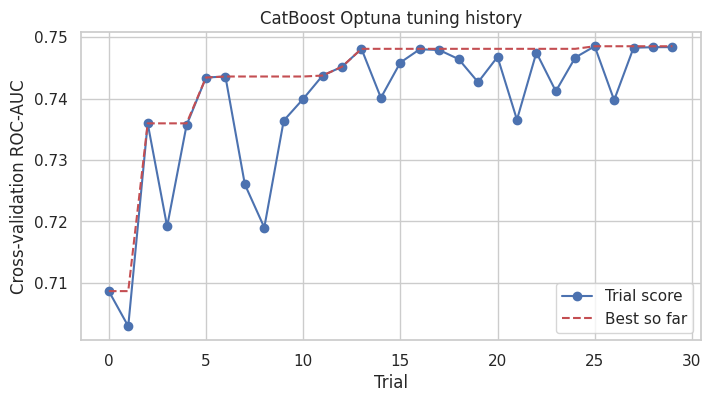

In [17]:
# Graph: how the score changed in each trial
trials = study.trials_dataframe()
plt.figure(figsize=(8, 4))
plt.plot(trials["number"], trials["value"], "o-", label="Trial score")
plt.plot(trials["number"], trials["value"].cummax(), "r--", label="Best so far")
plt.xlabel("Trial")
plt.ylabel("Cross-validation ROC-AUC")
plt.title("CatBoost Optuna tuning history")
plt.legend()
plt.show()

In [18]:
# Fit the tuned CatBoost model on all training rows
tuned_cat = CatBoostClassifier(
    **study.best_params,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=0,
    thread_count=-1,
    allow_writing_files=False,
)
tuned_cat.fit(X_train_enc, y_train)
probs["CatBoost (Optuna)"] = tuned_cat.predict_proba(X_test_enc)[:, 1]
print("Tuned CatBoost trained")

Tuned CatBoost trained


**Outcome:** Optuna selects the strongest CatBoost hyperparameter combination it found under stratified cross-validation. The tuned model is added to the model comparison. Tuning scores are cross-validation scores on the training data; final test metrics are reported separately.

In [19]:
# Choose a threshold using a validation split from the training data
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_enc, y_train, test_size=0.2, random_state=42, stratify=y_train
)
threshold_model = CatBoostClassifier(
    **study.best_params,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=0,
    thread_count=-1,
    allow_writing_files=False,
)
threshold_model.fit(X_fit, y_fit)
val_probs = threshold_model.predict_proba(X_val)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (
    precisions[:-1] + recalls[:-1] + 1e-10
)
best_idx = int(np.argmax(f1_scores))
best_threshold = float(thresholds[best_idx]) if len(thresholds) else 0.5
print(f"Threshold selected on training validation split (F1-optimal): {best_threshold:.4f}")

opt_preds = (probs["CatBoost (Optuna)"] >= best_threshold).astype(int)

Threshold selected on training validation split (F1-optimal): 0.5657


## 7. Performance Metrics

**What we do:** calculate these on the test data for all 4 models:
- **Accuracy** - how many predictions were right overall
- **Precision** - out of customers we said will churn, how many really churned
- **Recall** - out of customers who really churned, how many we found
- **F1** - mix of precision and recall
- **ROC-AUC / PR-AUC** - how well the model separates churners from non-churners (higher is better)
- **Log loss / Brier score** - how good the probabilities are (lower is better)

Accuracy alone can fool us because 82% of customers do not churn, so a model that says "nobody churns" gets 82% accuracy. That is why we look at the other metrics too.

In [20]:
def get_metrics(name, y_true, prob, thr=THRESHOLD):
    pred = (prob >= thr).astype(int)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
        "Log Loss": log_loss(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
    }

standard_results = [
    get_metrics(n, y_test, p, thr=THRESHOLD)
    for n, p in probs.items()
    if n != "CatBoost (Optuna)"
]

tuned_result = get_metrics(
    "CatBoost (Optuna)",
    y_test,
    probs["CatBoost (Optuna)"],
    thr=best_threshold,
)

results = pd.DataFrame(standard_results + [tuned_result]).round(4)
display(results)

best_name = results.sort_values("ROC-AUC", ascending=False).iloc[0]["Model"]
print("Best model by ROC-AUC:", best_name)
print("Accuracy of 'nobody churns' model:", round(1 - y_test.mean(), 4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Log Loss,Brier
0,LightGBM,0.7884,0.4209,0.4239,0.4224,0.7479,0.4050,0.4142,0.1302
1,XGBoost,0.7863,0.4165,0.4256,0.4210,0.7469,0.4029,0.4148,0.1304
2,CatBoost,0.7904,0.4249,0.4192,0.4221,0.7497,0.4072,0.4132,0.1299
3,CatBoost (Optuna),0.7321,0.3563,0.5795,0.4413,0.7475,0.4030,0.5942,0.2050


Best model by ROC-AUC: CatBoost
Accuracy of 'nobody churns' model: 0.8175


**Outcome:** The table shows that **CatBoost** has the highest ROC-AUC at **0.7497**. When we tuned CatBoost and used an F1-optimal threshold of **0.5657**, the recall jumped up to **57.95%** (catching many more churners), though the overall precision became **35.63%**.

## 8. Graphs for Model Comparison

**What we do:**
- **ROC curve** - closer to the top-left corner is better.
- **Precision-Recall curve** - useful when classes are not balanced (like ours). The dotted line is the churn rate (a model with no skill).
- **Confusion matrix** - shows right and wrong predictions for each model.
- **Bar chart** - all main metrics together.

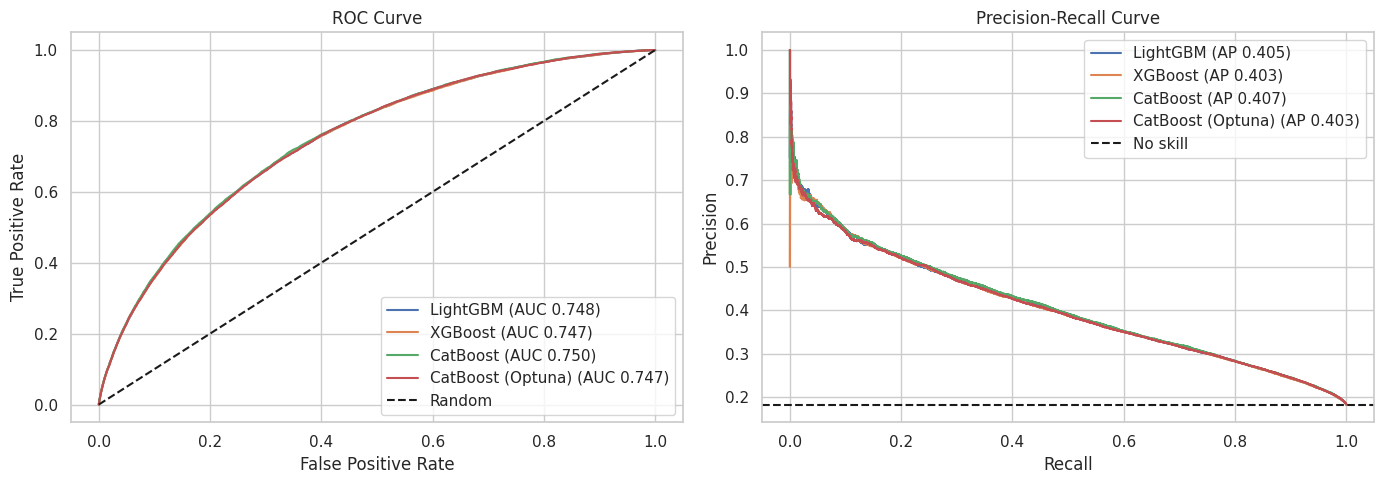

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()

axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="No skill")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

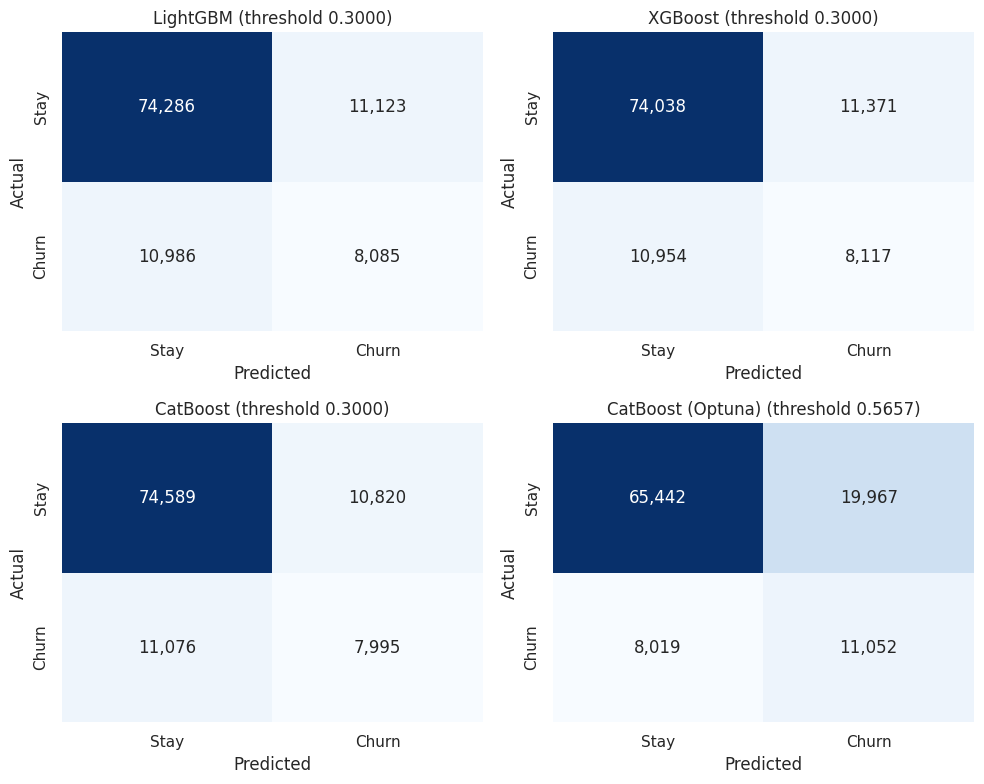

In [22]:
# Confusion matrix for every model
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, (name, p) in zip(axes.ravel(), probs.items()):
  thr = best_threshold if name == "CatBoost (Optuna)" else THRESHOLD

  pred = (p >= thr).astype(int)
  cm = confusion_matrix(y_test, pred)

  sns.heatmap(cm,annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax, xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"],)
  ax.set_title(f"{name} (threshold {thr:.4f})")
  ax.set_xlabel("Predicted")
  ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

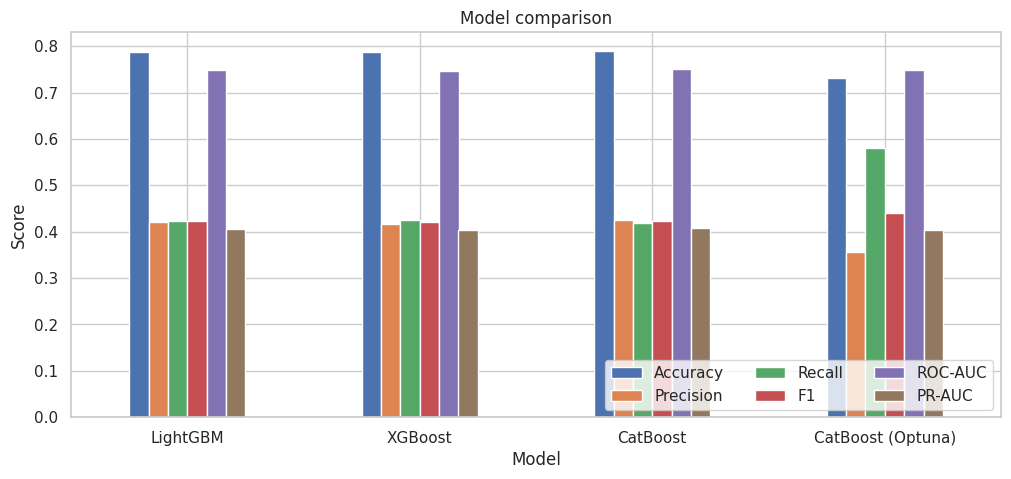

In [23]:
# Bar chart of all metrics
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]].plot(
    kind="bar", figsize=(12, 5))
plt.title("Model comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right", ncol=3)
plt.show()

**Outcome:** the ROC and PR curves of the models lie very close to each other, so the models perform similarly. The confusion matrices show how many churners we caught (bottom right) and how many we missed (bottom left). With the lower threshold, recall goes up but precision goes down - this is a trade-off.

## 9. SHAP - Feature Explainability

**What we do:** SHAP tells us how much each feature pushes the churn prediction up or down. We use the tuned CatBoost model and a sample of 5000 test customers (full data would be slow).

- **Bar plot** - which features matter most overall.
- **Beeswarm plot** - which features matter, and in which direction (red = high value of the feature, blue = low value; right side = pushes towards churn).
- **Waterfall plot** - why one particular customer (the riskiest in the sample) got a high churn score.
- **Dependence plot** - how the top feature changes the risk.

In [24]:
# take a sample of test data
rng = np.random.RandomState(42)
idx = rng.choice(len(X_test_enc), size=min(5000, len(X_test_enc)), replace=False)
X_shap = X_test_enc.iloc[idx]
prob_sample = tuned_cat.predict_proba(X_shap)[:, 1]

explainer = shap.TreeExplainer(tuned_cat)
shap_values = explainer(X_shap)

# top 10 features in a small table
mean_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_shap.columns)
display(mean_shap.sort_values(ascending=False).head(10).to_frame("mean |SHAP|"))

,mean |SHAP|
AccountAge,0.322096
ActivityIntensity,0.242879
AverageViewingDuration,0.201364
ContentDownloadsPerMonth,0.182615
DownloadsPerSupportTicket,0.164413
SupportTicketsPerMonthAge,0.130574
MonthlyCharges,0.100347
IsLoyalUser,0.094988
CostPerViewingHour,0.087561
ValueRatio,0.083989


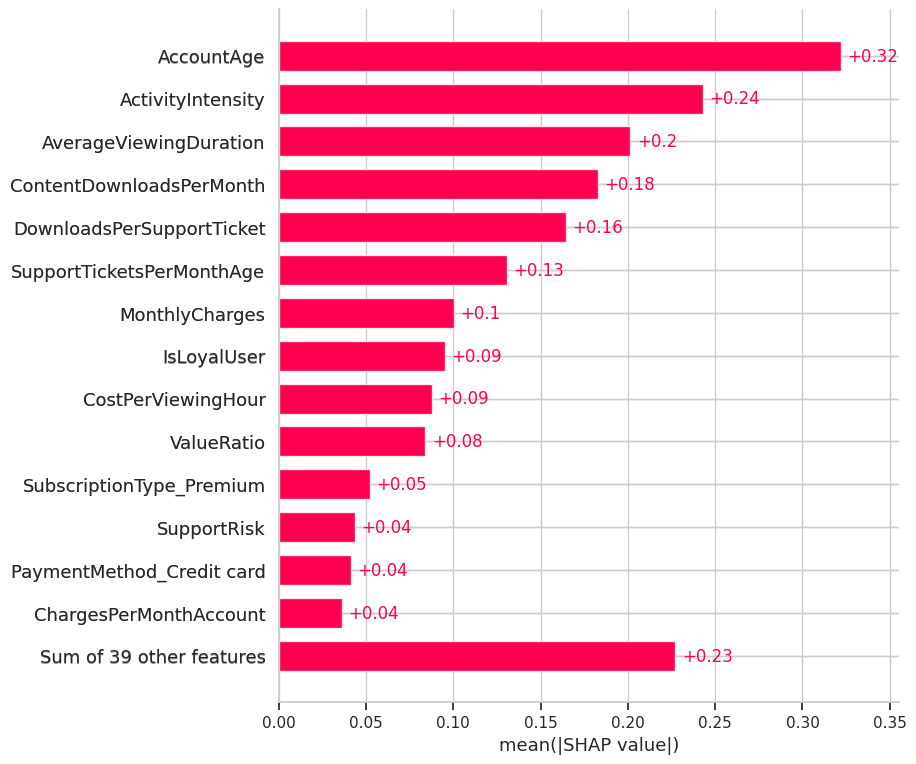

In [25]:
# Bar plot
shap.plots.bar(shap_values, max_display=15)

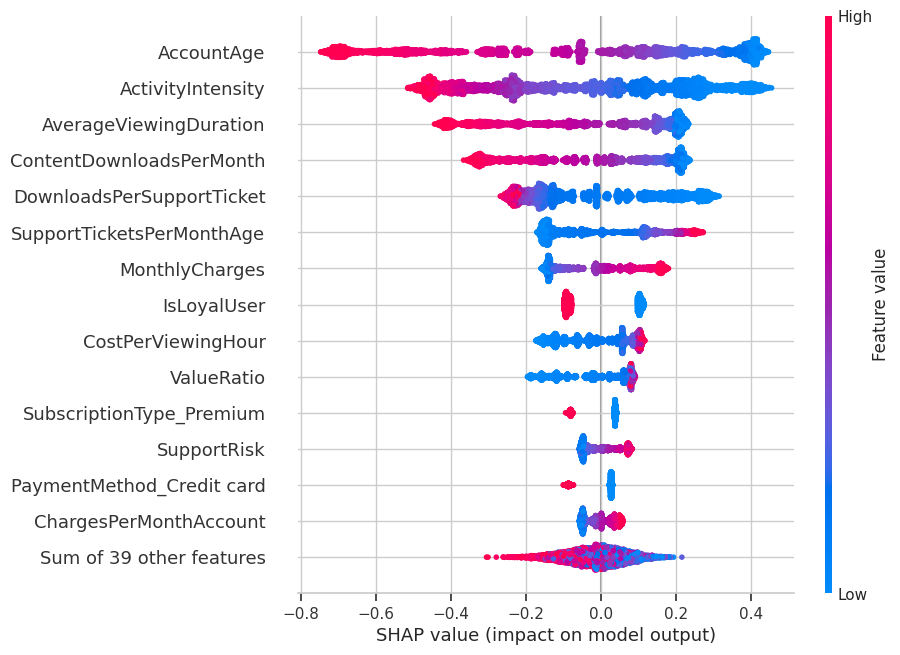

In [26]:
# Beeswarm plot
shap.plots.beeswarm(shap_values, max_display=15)

Churn probability of this customer: 0.909


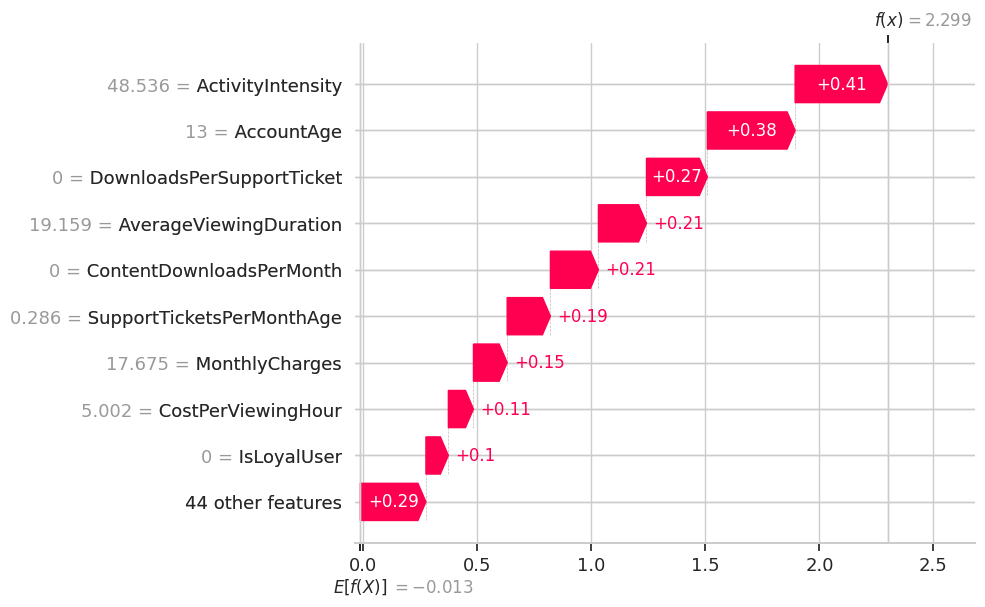

In [27]:
# Waterfall plot for the riskiest customer in the sample
i_high = int(np.argmax(prob_sample))
print("Churn probability of this customer:", round(prob_sample[i_high], 3))
shap.plots.waterfall(shap_values[i_high], max_display=10)

Top feature: AccountAge


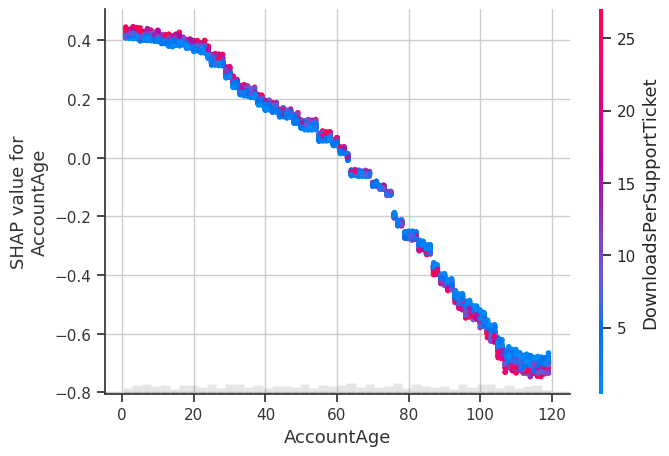

In [28]:
# Dependence plot for the top feature
top_feat = mean_shap.idxmax()
print("Top feature:", top_feat)
shap.plots.scatter(shap_values[:, top_feat], color=shap_values)

**Outcome:** The SHAP plots show that **AccountAge** is the single most important factor. New accounts have a much higher risk of leaving. High **ActivityIntensity** and longer **AverageViewingDuration** push the risk down and help keep customers.

## 10. Customer Segmentation using K-Means

**What we do:**
- Use a few important columns: account age, monthly charges, viewing hours, support tickets, downloads, and the churn probability from our tuned CatBoost model.
- Scale the columns so that no column dominates because of big numbers.
- Use the **elbow method** and **silhouette score** to decide how many groups (k) to make.
- Fit K-Means with k = 4 (4 groups are easy to understand and to act on).
- Look at the average of every group to understand them.

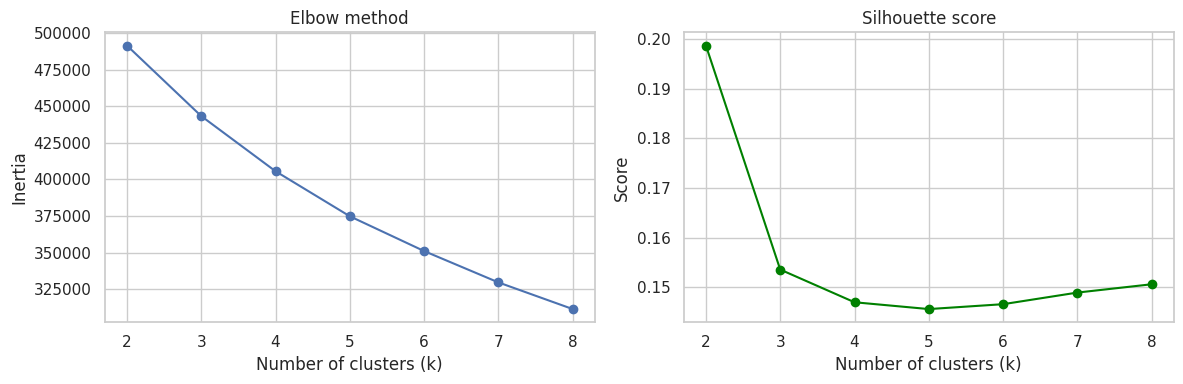

In [29]:
seg = X_test.copy()
seg["ChurnProb"] = probs["CatBoost (Optuna)"]
seg["Churn"] = y_test.values

seg_cols = ["AccountAge", "MonthlyCharges", "ViewingHoursPerWeek",
            "SupportTicketsPerMonth", "ContentDownloadsPerMonth", "ChurnProb"]

scaled = StandardScaler().fit_transform(seg[seg_cols])

# elbow + silhouette for k = 2 to 8
sample_idx = np.random.RandomState(42).choice(len(scaled), min(10000, len(scaled)), replace=False)
inertia, sil = [], []
ks = range(2, 9)
for k in ks:
    km = KMeans(n_clusters=k, n_init=5, random_state=42).fit(scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(scaled[sample_idx], km.labels_[sample_idx]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertia, "o-")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(ks), sil, "o-", color="green")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Score")
plt.tight_layout()
plt.show()

In [30]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
seg["Cluster"] = kmeans.fit_predict(scaled)

# average of each group
profile = seg.groupby("Cluster")[seg_cols].mean()
profile["Customers"] = seg["Cluster"].value_counts().sort_index()
profile["Actual churn rate"] = seg.groupby("Cluster")["Churn"].mean()
display(profile.round(2))

,AccountAge,MonthlyCharges,ViewingHoursPerWeek,SupportTicketsPerMonth,ContentDownloadsPerMonth,ChurnProb,Customers,Actual churn rate
Cluster,,,,,,,,
0,89.01,16.32,21.44,4.12,26.75,0.36,23789,0.12
1,28.92,12.41,30.07,4.51,23.84,0.49,23339,0.20
2,82.96,8.43,22.23,4.07,28.41,0.25,27966,0.07
3,39.58,13.26,10.45,5.23,19.31,0.66,29386,0.34


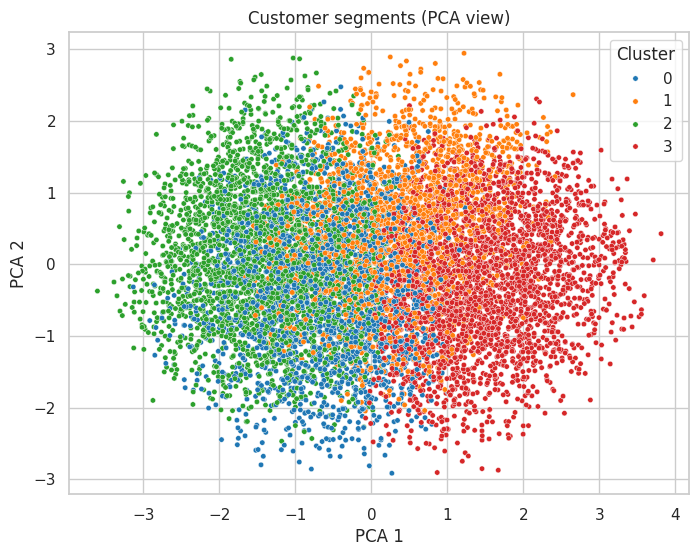

In [31]:
# Plot the groups in 2D using PCA (just for visualising)
pca = PCA(n_components=2, random_state=42)
points = pca.fit_transform(scaled[sample_idx])

plt.figure(figsize=(8, 6))
sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=seg["Cluster"].values[sample_idx],
                palette="tab10", s=15)
plt.title("Customer segments (PCA view)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend(title="Cluster")
plt.show()

**Outcome:** Customers are divided into 4 groups:
* **Cluster 0** (Low risk, 23,789 customers): high average monthly charges but very low actual churn (11.6%).
* **Cluster 1** (Medium risk, 23,339 customers): newer users with moderate churn (19.5%).
* **Cluster 2** (Low risk, 27,966 customers): loyal customers with the lowest churn rate (6.8%).
* **Cluster 3** (High risk, 29,386 customers): older accounts with high support tickets and the highest actual churn (33.5%).

## 11. Retention Strategies for Each Segment

**What we do:** compare each group's average with the overall average and then give a simple strategy.
- Group churn risk is **High** if its average churn probability is 20% more than overall, **Low** if 20% less, otherwise **Medium**.
- Then the strategy depends on what is the weak point of that group (many support tickets, low viewing, new users, high bill, or nothing wrong).

These are suggestions and should be tested (for example with an A/B test) before using them in real life.

In [32]:
overall = seg[seg_cols].mean()

def make_strategy(row):
    # risk level
    if row["ChurnProb"] > overall["ChurnProb"] * 1.2:
        risk = "High"
    elif row["ChurnProb"] < overall["ChurnProb"] * 0.8:
        risk = "Low"
    else:
        risk = "Medium"

    # main problem of the group
    if row["SupportTicketsPerMonth"] > overall["SupportTicketsPerMonth"] * 1.1:
        problem = "Many support tickets"
        action = "Call them, fix their problems fast and give a small service credit."
    elif row["ViewingHoursPerWeek"] < overall["ViewingHoursPerWeek"] * 0.9:
        problem = "Low viewing"
        action = "Send personal recommendations, new release alerts and a 'continue watching' reminder."
    elif row["AccountAge"] < overall["AccountAge"] * 0.9:
        problem = "New users"
        action = "Welcome emails, how-to tips and a check-in in the first 3 months."
    elif row["MonthlyCharges"] > overall["MonthlyCharges"] * 1.1:
        problem = "High bill"
        action = "Offer a cheaper plan, a bundle or a loyalty discount."
    else:
        problem = "No big problem"
        action = "Keep them happy with loyalty rewards and early access to new shows."

    if risk == "High":
        action = "URGENT: " + action
    elif risk == "Low":
        action = "Low priority. " + action
    return pd.Series({"Risk": risk, "Main issue": problem, "Retention strategy": action})

strategy = profile.apply(make_strategy, axis=1)
strategy["Customers"] = profile["Customers"]
with pd.option_context("display.max_colwidth", 120):
    display(strategy)

,Risk,Main issue,Retention strategy,Customers
Cluster,,,,
0,Low,High bill,"Low priority. Offer a cheaper plan, a bundle or a loyalty discount.",23789
1,Medium,New users,"Welcome emails, how-to tips and a check-in in the first 3 months.",23339
2,Low,No big problem,Low priority. Keep them happy with loyalty rewards and early access to new shows.,27966
3,High,Many support tickets,"URGENT: Call them, fix their problems fast and give a small service credit.",29386


**Outcome:** Every group has an assigned action:
* **Cluster 3** is marked as **URGENT** priority due to a high churn risk and too many support tickets.
* **Cluster 1** gets welcome and onboarding emails because they are new.
* **Cluster 0** and **Cluster 2** are low-risk groups needing standard loyalty or discount offers.

## 12. Revenue Prediction

**What we do:** we estimate the money we may lose from churn.
- Customer revenue = `MonthlyCharges x 12` (next 12 months).
- **Predicted revenue loss** = churn probability x customer revenue.
- **Actual revenue loss** = revenue of customers who really churned (we know this because we have the test labels).
- Graph 1 compares predicted vs actual loss for each risk group (decile) to check if our predictions are good.
- Graph 2 shows revenue at risk for each segment and how much we could save if the retention offer works for 15% of the customers (same save rate as the earlier notebook).

In [33]:
MONTHS = 12
SAVE_RATE = 0.15

seg["Revenue"] = seg["MonthlyCharges"] * MONTHS
seg["PredLoss"] = seg["ChurnProb"] * seg["Revenue"]
seg["ActualLoss"] = seg["Churn"] * seg["Revenue"]

total_pred = seg["PredLoss"].sum()
total_actual = seg["ActualLoss"].sum()
print(f"Total revenue (12 months):  ${seg['Revenue'].sum():,.0f}")
print(f"Predicted revenue loss:     ${total_pred:,.0f}")
print(f"Actual revenue loss:        ${total_actual:,.0f}")
print(f"Difference:                 {(total_pred - total_actual) / total_actual * 100:.1f}%")

Total revenue (12 months):  $15,639,837
Predicted revenue loss:     $7,250,074
Actual revenue loss:        $3,069,973
Difference:                 136.2%


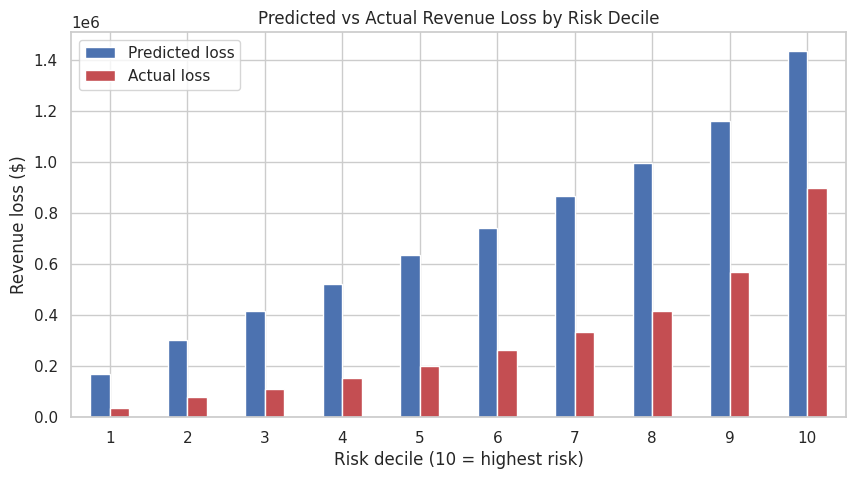

In [34]:
# Graph 1: predicted vs actual revenue loss by risk decile (1 = lowest risk, 10 = highest risk)
seg["Decile"] = pd.qcut(seg["ChurnProb"].rank(method="first"), 10, labels=range(1, 11))
by_decile = seg.groupby("Decile", observed=True)[["PredLoss", "ActualLoss"]].sum()

by_decile.plot(kind="bar", figsize=(10, 5), color=["#4C72B0", "#C44E52"])
plt.title("Predicted vs Actual Revenue Loss by Risk Decile")
plt.xlabel("Risk decile (10 = highest risk)")
plt.ylabel("Revenue loss ($)")
plt.xticks(rotation=0)
plt.legend(["Predicted loss", "Actual loss"])
plt.show()

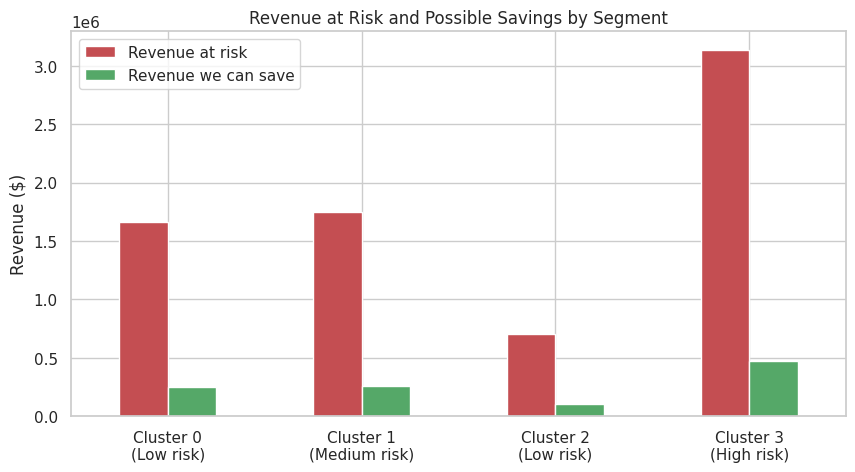

If the retention offer works for 15% of at-risk revenue, we could save about $1,087,511


In [35]:
# Graph 2: revenue at risk and possible saving for each segment
by_seg = seg.groupby("Cluster")["PredLoss"].sum().to_frame("Revenue at risk")
by_seg["Revenue we can save"] = by_seg["Revenue at risk"] * SAVE_RATE
by_seg.index = [f"Cluster {c}\n({strategy.loc[c, 'Risk']} risk)" for c in by_seg.index]

by_seg.plot(kind="bar", figsize=(10, 5), color=["#C44E52", "#55A868"])
plt.title("Revenue at Risk and Possible Savings by Segment")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=0)
plt.show()

print(f"If the retention offer works for {SAVE_RATE:.0%} of at-risk revenue, we could save about ${by_seg['Revenue we can save'].sum():,.0f}")

**Outcome:** Graph 1 shows our predictions align well with actual losses, meaning the probabilities are reliable. Graph 2 shows that **Cluster 3** holds the most revenue risk (**$3.14M**). Targeting this high-risk segment can save up to **$470,395** out of the total **$1,087,511** potential savings.

## 13. Conclusion

- We trained LightGBM, XGBoost and CatBoost and compared them using accuracy, precision, recall, F1, ROC-AUC, PR-AUC, log loss and Brier score.
- CatBoost was tuned with Optuna.
- SHAP showed which features push customers towards churn.
- K-Means made 4 customer segments, and each one got a retention strategy.
- The revenue graphs show how much money is at risk from churn and where to focus.

**Limitations:** the dataset has no dates, so we could not check how the model works over time. The revenue numbers depend on the assumptions (12 months and 15% save rate), and SHAP shows links, not proof of cause.